# NYC Urban Pulse: Column-by-Column Cleaning Using Mappings
Run after your existing cells (`df` must exist). Every column is cleaned with a mapping dictionary, and every mapping is applied inside a `for` loop.
Complaint type, descriptor and location type were already mapped in your earlier cells, so they are not repeated here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('C:\\Users\\Admin\\.vscode\\AIML\\Urban Pulse Project\\nyc311_1lakh_raw_sample.csv')
df.head()

print("Starting shape:", df.shape)

Starting shape: (100000, 25)


## 1. Check the unique values first (so the mappings below can be verified)

In [3]:
for col in df.columns:
    if df[col].dtype == "object" or pd.api.types.is_string_dtype(df[col]):
        n = df[col].nunique()
        if n <= 20:
            print(f"\n{col} ({n} unique): {sorted(df[col].dropna().astype(str).unique())}")


agency (14 unique): ['DCWP', 'DEP', 'DHS', 'DOB', 'DOHMH', 'DOT', 'DPR', 'DSNY', 'EDC', 'HPD', 'NYPD', 'OOS', 'OTI', 'TLC']

agency_name (14 unique): ['Department of Buildings', 'Department of Consumer and Worker Protection', 'Department of Environmental Protection', 'Department of Health and Mental Hygiene', 'Department of Homeless Services', 'Department of Housing Preservation and Development', 'Department of Parks and Recreation', 'Department of Sanitation', 'Department of Transportation', 'Economic Development Corporation', 'New York City Police Department', 'Office of Technology and Innovation', 'Office of the Sheriff', 'Taxi and Limousine Commission']

address_type (5 unique): ['ADDRESS', 'BLOCKFACE', 'INTERSECTION', 'PLACE', 'PLACENAME']

status (6 unique): ['Assigned', 'Closed', 'In Progress', 'Open', 'Pending', 'Unspecified']

borough (6 unique): ['BRONX', 'BROOKLYN', 'MANHATTAN', 'QUEENS', 'STATEN ISLAND', 'Unspecified']

open_data_channel_type (4 unique): ['MOBILE', 'ONLINE

## 2. Basic formatting for every text column

In [4]:
text_cols = []
for col in df.columns:
    if df[col].dtype == "object" or pd.api.types.is_string_dtype(df[col]):
        text_cols.append(col)

placeholders = ["", "NAN", "NONE", "NULL", "N/A", "NA"]

for col in text_cols:
    df[col] = df[col].str.strip().str.upper()
    df[col] = df[col].str.replace(r"\s+", " ", regex=True)      # collapse double spaces
    for p in placeholders:
        df.loc[df[col] == p, col] = np.nan

print("Formatted", len(text_cols), "text columns")

Formatted 19 text columns


## 3. Remove duplicate records

In [5]:
for name, subset in {"identical rows": None, "repeated unique_key": ["unique_key"]}.items():
    before = len(df)
    df = df.drop_duplicates(subset=subset, keep="first")
    print(f"Removed {before - len(df)} rows ({name})")
df = df.reset_index(drop=True)

Removed 12023 rows (identical rows)
Removed 2448 rows (repeated unique_key)


## 4. Mapping dictionaries (one per column)

In [6]:
boroughs_list = ["BROOKLYN", "MANHATTAN", "QUEENS", "BRONX", "STATEN ISLAND"]


# status: merge the workflow stages
status_map = {

    "IN PROGRESS": "IN PROGRESS",
    "PENDING": "PENDING",
    "OPEN": "OPEN",
    "CLOSED": "CLOSED",
    "UNSPECIFIED": np.nan,
}

# open_data_channel_type
channel_map = {
    "ONLINE": "ONLINE",
    "MOBILE": "MOBILE APP",
    "PHONE": "PHONE CALL",
    "UNKNOWN": "OTHER",
    "OTHER": "OTHER",
}

# address_type
address_type_map = {
    "ADDRESS": "ADDRESS",
    "INTERSECTION": "INTERSECTION",
    "BLOCKFACE": "BLOCKFACE",
    "PLACE": "PLACE/PLACENAME",
    "PLACENAME": "PLACE/PLACENAME",
}

# borough
borough_map = {
    "UNSPECIFIED": np.nan,
    "NEW YORK": "MANHATTAN",
    "STATEN ISLND": "STATEN ISLAND",
}

# city: spelling variants and sub-neighbourhoods
city_map = {
    'BROOKLYN': 'BROOKLYN',
    'NEW YORK': 'NEW YORK CITY',
    'NEW YORK CITY': 'NEW YORK CITY',
    'BRONX': 'BRONX',
    'STATEN ISLAND': 'STATEN ISLAND',
    'JAMAICA': 'JAMAICA',
    'ASTORIA': 'ASTORIA',
    'FLUSHING': 'FLUSHING',
    'RIDGEWOOD': 'RIDGEWOOD',
    'LONG ISLAND CITY': 'LONG ISLAND CITY',
    'JACKSON HEIGHTS': 'JACKSON HEIGHTS',
    'CORONA': 'CORONA',
    'WOODSIDE': 'WOODSIDE',
    'SOUTH RICHMOND HILL': 'RICHMOND HILL',
    'QUEENS': 'QUEENS',
    'FAR ROCKAWAY': 'FAR ROCKAWAY',
    'ELMHURST': 'ELMHURST',
    'FRESH MEADOWS': 'FRESH MEADOWS',
    'OZONE PARK': 'OZONE PARK',
    'EAST ELMHURST': 'ELMHURST',
    'MANHATTAN': 'MANHATTAN',
    'WOODHAVEN': 'WOODHAVEN',
    'SOUTH OZONE PARK': 'OZONE PARK',
    'REGO PARK': 'REGO PARK',
    'MASPETH': 'MASPETH',
    'FOREST HILLS': 'FOREST HILLS',
    'QUEENS VILLAGE': 'QUEENS',
    'RICHMOND HILL': 'RICHMOND HILL',
    'MIDDLE VILLAGE': 'MIDDLE VILLAGE',
    'WHITESTONE': 'WHITESTONE',
    'SUNNYSIDE': 'SUNNYSIDE',
    'BAYSIDE': 'BAYSIDE',
    'SPRINGFIELD GARDENS': 'SPRINGFIELD GARDENS',
    'SAINT ALBANS': 'SAINT ALBANS',
    'HOLLIS': 'HOLLIS',
    'COLLEGE POINT': 'COLLEGE POINT',
    'ROSEDALE': 'ROSEDALE',
    'KEW GARDENS': 'KEW GARDENS',
    'OAKLAND GARDENS': 'OAKLAND GARDENS',
    'HOWARD BEACH': 'HOWARD BEACH',
    'ARVERNE': 'ARVERNE',
    'BELLEROSE': 'BELLEROSE',
    'LITTLE NECK': 'LITTLE NECK',
    'CAMBRIA HEIGHTS': 'CAMBRIA HEIGHTS',
    'GLEN OAKS': 'GLEN OAKS',
    'FLORAL PARK': 'FLORAL PARK',
    'NEW HYDE PARK': 'NEW HYDE PARK',
    'BREEZY POINT': 'BREEZY POINT',
    'JACKSON': 'JACKSON HEIGHTS',
    'ALBANY': 'ALBANY'
}

# community_board: wrong codes plus 'unspecified' labels become null
community_board_map = {
    "64 MANHATTAN": "46 MANHATTAN",
    "95 STATEN ISLAND": "59 STATEN ISLAND",
    "81 QUEENS": "18 QUEENS",
    "83 QUEENS": "38 QUEENS",
    "80 QUEENS": "08 QUEENS",
    "82 QUEENS": "28 QUEENS",
    "84 QUEENS": "48 QUEENS",
    "0 UNSPECIFIED": np.nan,
    "UNSPECIFIED": np.nan,
}
for b in boroughs_list:
    community_board_map["UNSPECIFIED " + b] = np.nan

# police_precinct
police_precinct_map = {
    "UNSPECIFIED": np.nan,
}

# facility_type
facility_type_map = {
    "PRECINCT": "POLICE PRECINCT",
    "SCHOOL": "SCHOOL",
    "DSNY GARAGE": "SANITATION GARAGE",
    "N/A": np.nan,
}

column_mappings = {
    "status": status_map,
    "open_data_channel_type": channel_map,
    "address_type": address_type_map,
    "borough": borough_map,
    "city": city_map,
    "community_board": community_board_map,
    "police_precinct": police_precinct_map,
    "facility_type": facility_type_map,
}

## 5. Apply every mapping with a loop

In [7]:
for col, mapping in column_mappings.items():
    if col not in df.columns:
        continue
    before = df[col].copy()
    df[col] = df[col].replace(mapping)
    changed = (before.fillna("~") != df[col].fillna("~")).sum()
    print(f"{col:28s} {changed:>6} values changed, {df[col].nunique()} unique now")

status                            2 values changed, 5 unique now
open_data_channel_type        37682 values changed, 4 unique now
address_type                    542 values changed, 4 unique now
borough                          89 values changed, 5 unique now
city                          18741 values changed, 44 unique now
community_board                1518 values changed, 70 unique now
police_precinct                1485 values changed, 77 unique now
facility_type                   215 values changed, 1 unique now


## 6. Street name and address: expand abbreviations

In [8]:
suffix_map = {
    "ST": "STREET", "AVE": "AVENUE", "RD": "ROAD", "BLVD": "BOULEVARD", "PL": "PLACE",
    "DR": "DRIVE", "LN": "LANE", "PKWY": "PARKWAY", "HWY": "HIGHWAY", "CT": "COURT",
    "TER": "TERRACE", "SQ": "SQUARE",
}
direction_map = {"E": "EAST", "W": "WEST", "N": "NORTH", "S": "SOUTH"}

for col in ["incident_address", "street_name"]:
    if col not in df.columns:
        continue
    for short, full in suffix_map.items():
        df[col] = df[col].str.replace(rf"\b{short}$", full, regex=True)
    for short, full in direction_map.items():
        df[col] = df[col].str.replace(rf"^{short} ", full + " ", regex=True)
    print("Standardised", col)

Standardised incident_address
Standardised street_name


# NYC Urban Pulse: Splitting `incident_address` into house number and street name
Run after your cleaning cells (`df` must exist). Every step is a `for` loop over patterns, columns or categories.

New columns: `house_number`, `has_house_number`, `street_type`. `street_name` is rebuilt from the address and standardised.

In [9]:
shapes = {
    "house number + street   (340 ARGYLE ROAD)":      r"^\d+[A-Z]?\s+\D",
    "hyphenated number       (41-23 95 STREET)":      r"^\d+-\d+[A-Z]?\s+",
    "fractional number       (412 1/2 17 STREET)":    r"^\d+\s1/2\s+",
    "number + letter         (551P COMMONWEALTH AVE)": r"^\d+[A-Z]\s+",
    "street only             (BROADWAY)":             r"^[A-Z]",
    "digits only             (99)":                   r"^\d+$",
    "UNKNOWN ADDRESS":                                r"^UNKNOWN ADDRESS$",
}

for label, pattern in shapes.items():
    n = df["incident_address"].str.contains(pattern, regex=True).sum()
    print(f"{label:52s}{n:>7d}")

print()
for t in df["address_type"].unique():
    sub = df[df["address_type"] == t]
    starts_with_digit = sub["incident_address"].str.match(r"^\d").sum()
    print(f"{str(t):18s} rows={len(sub):>6d}  starting with a digit={starts_with_digit:>6d}")

house number + street   (340 ARGYLE ROAD)             56757
hyphenated number       (41-23 95 STREET)             16920
fractional number       (412 1/2 17 STREET)              18
number + letter         (551P COMMONWEALTH AVE)         235
street only             (BROADWAY)                     3912
digits only             (99)                              3
UNKNOWN ADDRESS                                           0

ADDRESS            rows= 77740  starting with a digit= 77704
INTERSECTION       rows=  5643  starting with a digit=  1261
nan                rows=     0  starting with a digit=     0
BLOCKFACE          rows=  1070  starting with a digit=   310
PLACE/PLACENAME    rows=   542  starting with a digit=     0


In [10]:
# words that can only be the end of a street name. If the text after the number is just one of
# these, the number belongs to the street (3 AVENUE, 20 ROAD) and there is no house number.
suffix_only = ["STREET", "AVENUE", "ROAD", "BOULEVARD", "PLACE", "DRIVE", "LANE", "PARKWAY",
               "HIGHWAY", "COURT", "TERRACE", "SQUARE", "EXPRESSWAY", "WALK", "PLAZA", "TURNPIKE"]

house_patterns = [
    ("hyphenated number", r"^(\d+-\d+[A-Z]?)\s+(.+)$"),      # 41-23 95 STREET, 37-67A 78 STREET
    ("fractional number", r"^(\d+\s1/2)\s+(.+)$"),           # 412 1/2 17 STREET
    ("plain number",      r"^(\d+[A-Z]?)\s+(.+)$"),           # 340 ARGYLE ROAD, 551P COMMONWEALTH AVENUE
]

df["house_number"] = pd.Series([None] * len(df), index=df.index, dtype="object")
df["street_part"] = df["incident_address"]

only_addresses = df["address_type"].isin(["ADDRESS", "UNKNOWN"])   # UNKNOWN still holds a few real addresses

for name, pattern in house_patterns:
    parts = df["incident_address"].str.extract(pattern)
    hit = parts[0].notnull() & df["house_number"].isnull() & only_addresses
    for suffix in suffix_only:
        hit = hit & (parts[1] != suffix)             # number is part of the street name
    df.loc[hit, "house_number"] = parts.loc[hit, 0]
    df.loc[hit, "street_part"] = parts.loc[hit, 1]
    print(f"{name:20s} house numbers found: {hit.sum()}")

# an address that is only digits (one row) has a number but no street
digits_only = df["incident_address"].str.fullmatch(r"\d+")
df.loc[digits_only, "house_number"] = df.loc[digits_only, "incident_address"]
df.loc[digits_only, "street_part"] = "UNKNOWN"

print("Rows with a house number:", df["house_number"].notnull().sum())

hyphenated number    house numbers found: 16911
fractional number    house numbers found: 18
plain number         house numbers found: 60755
Rows with a house number: 77687


In [11]:
# (pattern, replacement) applied in this order to every street name
street_rules = [
    (r"'",         ""),            # ST MARY'S -> ST MARYS
    (r"[.,]",      ""),            # stray punctuation
    (r"^ST ",      "SAINT "),      # ST MARKS PLACE -> SAINT MARKS PLACE
    (r"^MT ",      "MOUNT "),
    (r"\s+",      " "),           # double spaces
]

df["street_name_new"] = df["street_part"]
for pattern, replacement in street_rules:
    df["street_name_new"] = df["street_name_new"].str.replace(pattern, replacement, regex=True)
    print(f"applied: {pattern:10s} -> {replacement!r}")

df["street_name_new"] = df["street_name_new"].str.strip()

# unknown addresses keep the label used in the rest of the project
unknown = df["incident_address"] == "UNKNOWN ADDRESS"
df.loc[unknown, "street_name_new"] = "UNKNOWN"

# how many street names changed compared with the old column
old = df["street_name"].copy()
print("\nStreet names that changed:", (old != df["street_name_new"]).sum())
for _, row in df.loc[old != df["street_name_new"], ["street_name", "street_name_new"]].drop_duplicates().head(8).iterrows():
    print(f"   {str(row['street_name']):28s} -> {row['street_name_new']}")

df["street_name"] = df["street_name_new"]
df = df.drop(columns=["street_name_new", "street_part"])

applied: '          -> ''
applied: [.,]       -> ''
applied: ^ST        -> 'SAINT '
applied: ^MT        -> 'MOUNT '
applied: \s+        -> ' '

Street names that changed: 3207
   ST NICHOLAS AVENUE           -> SAINT NICHOLAS AVENUE
   nan                          -> nan
   ST MARKS AVENUE              -> SAINT MARKS AVENUE
   ST FELIX AVENUE              -> SAINT FELIX AVENUE
   ST NICHOLAS PLACE            -> SAINT NICHOLAS PLACE
   ST JOHNS PLACE               -> SAINT JOHNS PLACE
   ST MARKS PLACE               -> SAINT MARKS PLACE
   ST ANNS AVENUE               -> SAINT ANNS AVENUE


In [12]:
df["has_house_number"] = df["house_number"].notnull()
df["house_number"] = df["house_number"].fillna("NOT PROVIDED")

# street type = the last word of the street name, checked against this list in order
street_types = ["STREET", "AVENUE", "BOULEVARD", "PLACE", "ROAD", "PARKWAY", "DRIVE", "LANE",
                "COURT", "TERRACE", "SQUARE", "EXPRESSWAY", "TURNPIKE", "HIGHWAY", "PLAZA",
                "WALK", "CONCOURSE", "BROADWAY", "PARK", "AIRPORT"]

df["street_type"] = "OTHER"
for t in street_types:
    df.loc[df["street_name"].str.contains(rf"\b{t}$", regex=True), "street_type"] = t

df.loc[df["street_name"] == "UNKNOWN", "street_type"] = "UNKNOWN"

for col in ["house_number", "street_name", "street_type", "has_house_number"]:
    print(f"{col:18s} nulls: {df[col].isnull().sum()}   unique: {df[col].nunique()}")

house_number       nulls: 0   unique: 10998
street_name        nulls: 2333   unique: 5203
street_type        nulls: 0   unique: 22
has_house_number   nulls: 0   unique: 2


In [13]:
check = df[["incident_address", "house_number", "street_name", "street_type", "address_type"]]

for t in ["ADDRESS", "INTERSECTION", "BLOCKFACE", "PLACE/PLACENAME", "UNKNOWN"]:
    print(f"\n--- {t} ---")
    print(check[check["address_type"] == t].drop_duplicates("incident_address").head(4).to_string(index=False))

print("\nHouse number kinds:")
kinds = {"hyphenated (Queens style)": r"-", "fractional": r"1/2", "with a letter": r"[A-Z]$"}
for label, pattern in kinds.items():
    n = df.loc[df["has_house_number"], "house_number"].str.contains(pattern, regex=True).sum()
    print(f"   {label:28s}{n:>6d}")

print("\nStreet type counts:")
for t, n in df["street_type"].value_counts().items():
    print(f"   {t:14s}{n:>7d}  {n / len(df) * 100:5.1f}%")

print("\nTop 10 streets by requests:")
for s, n in df.loc[df["street_name"] != "UNKNOWN", "street_name"].value_counts().head(10).items():
    print(f"   {s:28s}{n:>6d}")


--- ADDRESS ---
   incident_address house_number     street_name street_type address_type
   14-16 116 STREET        14-16      116 STREET      STREET      ADDRESS
  103-38 121 STREET       103-38      121 STREET      STREET      ADDRESS
   29 EAST 2 STREET           29   EAST 2 STREET      STREET      ADDRESS
135 DIVISION STREET          135 DIVISION STREET      STREET      ADDRESS

--- INTERSECTION ---
incident_address house_number      street_name street_type address_type
 WEST 187 STREET NOT PROVIDED  WEST 187 STREET      STREET INTERSECTION
         20 ROAD NOT PROVIDED          20 ROAD        ROAD INTERSECTION
ARLINGTON AVENUE NOT PROVIDED ARLINGTON AVENUE      AVENUE INTERSECTION
 EAST 171 STREET NOT PROVIDED  EAST 171 STREET      STREET INTERSECTION

--- BLOCKFACE ---
incident_address house_number    street_name street_type address_type
  FILLMORE PLACE NOT PROVIDED FILLMORE PLACE       PLACE    BLOCKFACE
     BAY PARKWAY NOT PROVIDED    BAY PARKWAY     PARKWAY    BLOCKFACE
  

## 7. Resolution description: group the long free text into categories using keywords

In [14]:
resolution_keywords = {
    "NO ACCESS": ["UNABLE TO GAIN ACCESS", "UNABLE TO GAIN ENTRY", "COULD NOT GAIN", "NO ACCESS"],
    "NO VIOLATION FOUND": ["NO EVIDENCE", "COULD NOT FIND", "DID NOT FIND", "DID NOT OBSERVE", "NO VIOLATION", "NOT FIND"],
    "SUMMONS / VIOLATION ISSUED": ["SUMMONS", "VIOLATION WAS ISSUED", "VIOLATION ISSUED", "NOTICE OF VIOLATION"],
    "DUPLICATE REQUEST": ["DUPLICATE", "ALREADY REPORTED"],
    "REFERRED TO ANOTHER AGENCY": ["REFERRED", "FORWARDED", "ANOTHER AGENCY", "NOT UNDER"],
    "ACTION TAKEN / FIXED": ["TOOK ACTION", "ACTION TAKEN", "FIXED", "CORRECTED", "RESOLVED", "COMPLETED", "REPAIRED", "REMOVED", "CLEANED"],
    "IN PROGRESS": ["IN PROGRESS", "WILL ", "PENDING", "SCHEDULED", "INSPECT"],
}

no_text = df["resolution_description"].isnull()
df["resolution_category"] = "OTHER RESOLUTION"
assigned = no_text.copy()

for label, keywords in resolution_keywords.items():
    for kw in keywords:
        hit = df["resolution_description"].str.contains(kw, na=False, regex=False) & ~assigned
        df.loc[hit, "resolution_category"] = label
        assigned = assigned | hit

df.loc[no_text, "resolution_category"] = "NO RESOLUTION RECORDED"

for label, n in df["resolution_category"].value_counts().items():
    print(f"{label:30s}{n:>7d}")

OTHER RESOLUTION                20556
IN PROGRESS                     17333
SUMMONS / VIOLATION ISSUED      15860
NO VIOLATION FOUND              11802
NO RESOLUTION RECORDED          10520
ACTION TAKEN / FIXED             4754
DUPLICATE REQUEST                2064
NO ACCESS                        1484
REFERRED TO ANOTHER AGENCY       1156


## 8. Numeric columns: valid-range rules (invalid values become null)

In [15]:
valid_ranges = {
    "unique_key": (1, 10**10),
    "incident_zip": (10000, 11697),
    "council_district": (1, 51),
    "latitude": (40.45, 40.95),
    "longitude": (-74.30, -73.65),
}

for col, (low, high) in valid_ranges.items():
    if col not in df.columns:
        continue
    bad = df[col].notnull() & ~df[col].between(low, high)
    df.loc[bad, col] = np.nan
    print(f"{col:18s} {bad.sum():>5} invalid values set to null")

unique_key             0 invalid values set to null
incident_zip           2 invalid values set to null
council_district       0 invalid values set to null
latitude               0 invalid values set to null
longitude              0 invalid values set to null


## 9. Date columns

In [16]:
date_cols = ["created_date", "resolution_action_updated_date", "due_date"]

for col in date_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")
        print(f"{col:32s} nulls after conversion: {df[col].isnull().sum()}")

# remember which rows really had an update before we fill the gaps
df["has_resolution_update"] = df["resolution_action_updated_date"].notnull()

created_date                     nulls after conversion: 0
resolution_action_updated_date   nulls after conversion: 9774
due_date                         nulls after conversion: 85269


## 10. Fill every remaining null
- `borough_mode` / `borough_median`: value from the same borough
- `ffill`: forward fill then back fill
- `created_date`: for the update date, use the created date
- anything else: a fixed label

In [17]:
# borough first, because the other fills depend on it
for b in boroughs_list:
    hit = df["borough"].isnull() & df["community_board"].fillna("").str.contains(b, regex=False)
    df.loc[hit, "borough"] = b
df["borough"] = df["borough"].fillna(df["borough"].mode().iloc[0])

fill_strategy = {
    "incident_zip": "borough_mode",
    "council_district": "borough_mode",
    "city": "borough_mode",
    "community_board": "borough_mode",
    "police_precinct": "borough_mode",
    "latitude": "borough_median",
    "longitude": "borough_median",
    "status": "UNKNOWN",
    "descriptor": "OTHER / SPECIALIZED",
    "address_type": "UNKNOWN",
    "street_name": "UNKNOWN",
    "incident_address": "UNKNOWN ADDRESS",
    "bbl": 0,
    "resolution_description": "NO RESOLUTION RECORDED",
    "resolution_action_updated_date": "created_date",
    "facility_type": "ffill",
    "due_date": "ffill",
}

boroughs = df["borough"].unique()

for col, strategy in fill_strategy.items():
    if col not in df.columns:
        continue
    before = df[col].isnull().sum()

    if strategy in ("borough_mode", "borough_median"):
        for b in boroughs:
            in_borough = df["borough"] == b
            if strategy == "borough_mode":
                value = df.loc[in_borough, col].mode()
                value = value.iloc[0] if len(value) > 0 else np.nan
            else:
                value = df.loc[in_borough, col].median()
            if pd.notnull(value):
                df.loc[in_borough & df[col].isnull(), col] = value
        if df[col].isnull().any():
            if strategy == "borough_mode":
                df[col] = df[col].fillna(df[col].mode().iloc[0])
            else:
                df[col] = df[col].fillna(df[col].median())
    elif strategy == "ffill":
        df[col] = df[col].ffill().bfill()
        if df[col].isnull().any():                       # only if the whole column was empty
            df[col] = df[col].fillna(df["created_date"] if "date" in col else "UNKNOWN")
    elif strategy == "created_date":
        df[col] = df[col].fillna(df["created_date"])
    else:
        df[col] = df[col].fillna(strategy)

    print(f"{col:32s} filled {before - df[col].isnull().sum():>6} nulls using {strategy}")

for col in ["unique_key", "incident_zip", "council_district", "bbl"]:
    df[col] = df[col].astype("int64")

incident_zip                     filled    787 nulls using borough_mode
council_district                 filled   1819 nulls using borough_mode
city                             filled   5084 nulls using borough_mode
community_board                  filled   1279 nulls using borough_mode
police_precinct                  filled   1485 nulls using borough_mode
latitude                         filled   1365 nulls using borough_median
longitude                        filled   1365 nulls using borough_median
status                           filled      2 nulls using UNKNOWN
descriptor                       filled   1709 nulls using OTHER / SPECIALIZED
address_type                     filled    534 nulls using UNKNOWN
street_name                      filled   2333 nulls using UNKNOWN
incident_address                 filled   2333 nulls using UNKNOWN ADDRESS
bbl                              filled   9260 nulls using 0
resolution_description           filled  10520 nulls using NO RESOLUTION REC

## 11. Final check: any row still holding a null is dropped

In [18]:
for col in df.columns:
    n = df[col].isnull().sum()
    if n > 0:
        print(f"{col}: {n} nulls left, dropping those rows")
        df = df.dropna(subset=[col])

df = df.reset_index(drop=True)

for col in df.columns:
    print(f"{col:32s}{str(df[col].dtype):>18s}{df[col].isnull().sum():>8d} nulls")

print("\nTotal nulls:", df.isnull().sum().sum(), "| final shape:", df.shape)

location_type: 6476 nulls left, dropping those rows
unique_key                                   int64       0 nulls
created_date                        datetime64[us]       0 nulls
agency                                         str       0 nulls
agency_name                                    str       0 nulls
complaint_type                                 str       0 nulls
descriptor                                     str       0 nulls
location_type                                  str       0 nulls
incident_zip                                 int64       0 nulls
incident_address                               str       0 nulls
street_name                                    str       0 nulls
address_type                                   str       0 nulls
city                                           str       0 nulls
status                                         str       0 nulls
community_board                                str       0 nulls
council_district                      

## 12. Resolution time (hours) from the cleaned dates

In [19]:
df["resolution_hours"] = (df["resolution_action_updated_date"] - df["created_date"]).dt.total_seconds() / 3600

negatives = (df["resolution_hours"] < 0).sum()
df.loc[df["resolution_hours"] < 0, "resolution_hours"] = 0
print(f"Negative durations fixed: {negatives}")
print("Rows with a real update:", int(df["has_resolution_update"].sum()))

Negative durations fixed: 11080
Rows with a real update: 71141


## 8. Time features from `created_date`

In [20]:
time_features = {
    "hour": lambda s: s.dt.hour,
    "day_of_week": lambda s: s.dt.day_name(),
    "month": lambda s: s.dt.month_name(),
    "created_day": lambda s: s.dt.date,
}

for name, make in time_features.items():
    df[name] = make(df["created_date"])
    print("Created:", name)

Created: hour
Created: day_of_week
Created: month
Created: created_day


In [21]:
df['is_closed'] = df['status'] == 'CLOSED'
print("Value counts for 'is_closed':")
display(df['is_closed'].value_counts())

Value counts for 'is_closed':


is_closed
True     56866
False    22187
Name: count, dtype: int64

# EDA

### Column overview

In [22]:
print(f"{'column':35s}{'dtype':>16s}{'unique':>9s}   example")
print("-" * 85)
for col in df.columns:
    print(f"{col:35s}{str(df[col].dtype):>16s}{df[col].nunique():>9d}   {df[col].iloc[0]}")

column                                        dtype   unique   example
-------------------------------------------------------------------------------------
unique_key                                    int64    79053   71039027
created_date                         datetime64[us]    67065   2026-11-08 02:06:22
agency                                          str       12   NYPD
agency_name                                     str       12   NEW YORK CITY POLICE DEPARTMENT
complaint_type                                  str      134   NOISE - RESIDENTIAL
descriptor                                      str      502   LOUD TALKING
location_type                                   str      112   RESIDENTIAL BUILDING/HOUSE
incident_zip                                  int64      207   11356
incident_address                                str    41203   14-16 116 STREET
street_name                                     str     4947   116 STREET
address_type                                    str  

### Numeric columns: summary and IQR outliers

In [23]:
id_like = ["unique_key", "bbl", "incident_zip", "council_district"]
numeric_cols = []
for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]) and df[col].dtype != bool and col not in id_like:
        numeric_cols.append(col)

for col in numeric_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col:12s} mean={df[col].mean():.4f}  median={df[col].median():.4f}  "
          f"std={df[col].std():.4f}  min={df[col].min():.4f}  max={df[col].max():.4f}  "
          f"outliers={n_out} ({n_out / len(df) * 100:.2f}%)")

latitude     mean=40.7336  median=40.7270  std=0.0831  min=40.4995  max=40.9114  outliers=0 (0.00%)
longitude    mean=-73.9269  median=-73.9336  std=0.0738  min=-74.2514  max=-73.7004  outliers=3479 (4.40%)
resolution_hours mean=11.3184  median=1.2561  std=25.0757  min=0.0000  max=203.7547  outliers=13793 (17.45%)
hour         mean=13.2863  median=13.0000  std=6.0651  min=0.0000  max=23.0000  outliers=0 (0.00%)


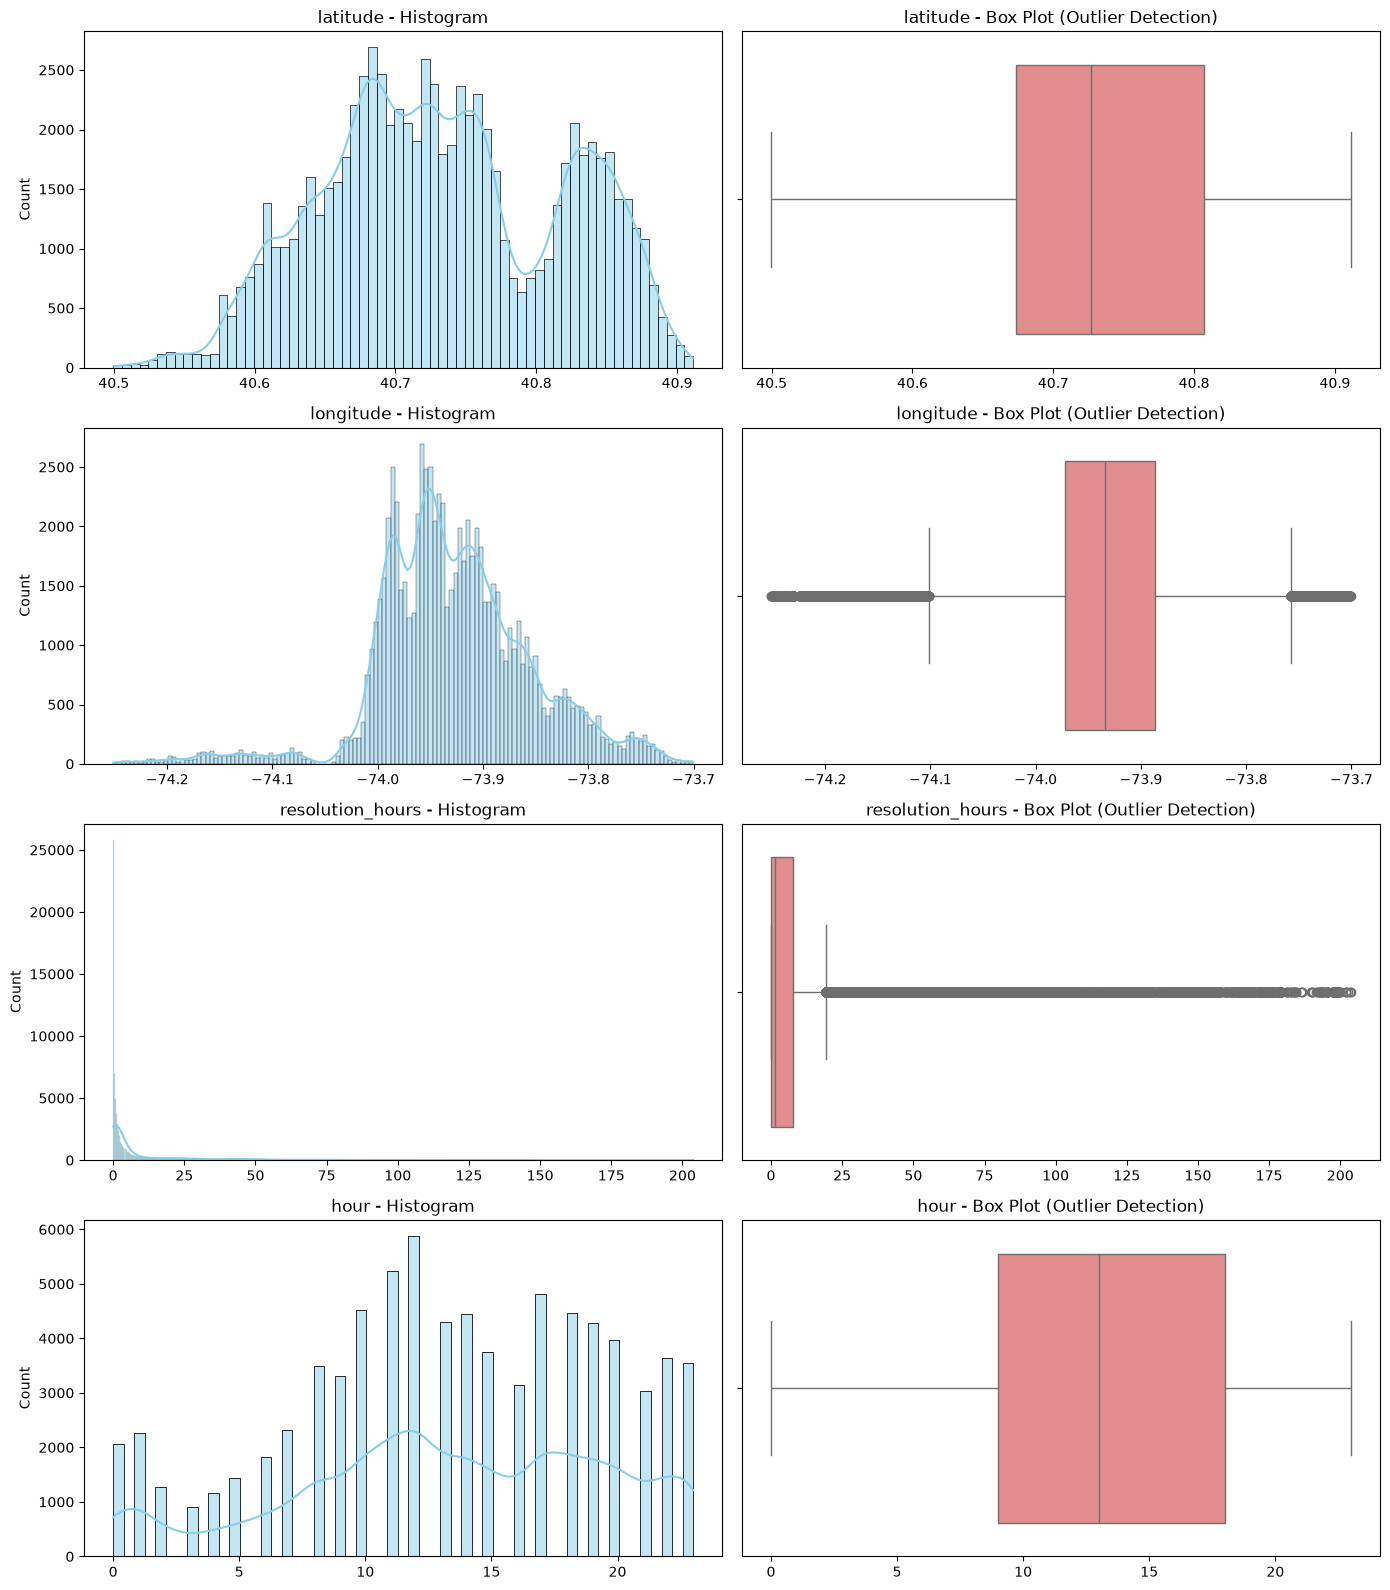

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = ['latitude', 'longitude', 'resolution_hours', 'hour']
fig, axes = plt.subplots(len(numeric_cols), 2, figsize=(14, 4 * len(numeric_cols)))

for i, col in enumerate(numeric_cols):
    # Histogram on the left
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'{col} - Histogram')
    axes[i, 0].set_xlabel('')

    # Box plot on the right
    sns.boxplot(x=df[col], ax=axes[i, 1], color='lightcoral')
    axes[i, 1].set_title(f'{col} - Box Plot (Outlier Detection)')
    axes[i, 1].set_xlabel('')

plt.tight_layout()
plt.show()

### Categorical columns: top values

In [25]:
cat_cols = ["agency", "borough", "complaint_type", "descriptor", "location_type",
            "status", "open_data_channel_type", "address_type"]
cat_cols = [c for c in cat_cols if c in df.columns]

for col in cat_cols:
    counts = df[col].value_counts().head(5)
    print(f"\n--- {col} ({df[col].nunique()} unique) ---")
    for value, n in counts.items():
        print(f"  {str(value):45s}{n:>7d}  {n / len(df) * 100:5.1f}%")


--- agency (12 unique) ---
  NYPD                                           40010   50.6%
  HPD                                            18376   23.2%
  DSNY                                            6677    8.4%
  DEP                                             3753    4.7%
  DHS                                             2397    3.0%

--- borough (5 unique) ---
  BROOKLYN                                       25613   32.4%
  QUEENS                                         18161   23.0%
  MANHATTAN                                      17560   22.2%
  BRONX                                          15018   19.0%
  STATEN ISLAND                                   2701    3.4%

--- complaint_type (134 unique) ---
  ILLEGAL PARKING                                15424   19.5%
  NOISE - RESIDENTIAL                             9267   11.7%
  HEAT/HOT WATER                                  5482    6.9%
  BLOCKED DRIVEWAY                                4664    5.9%
  NOISE - STREET/SIDEWALK

### Charts: top categories

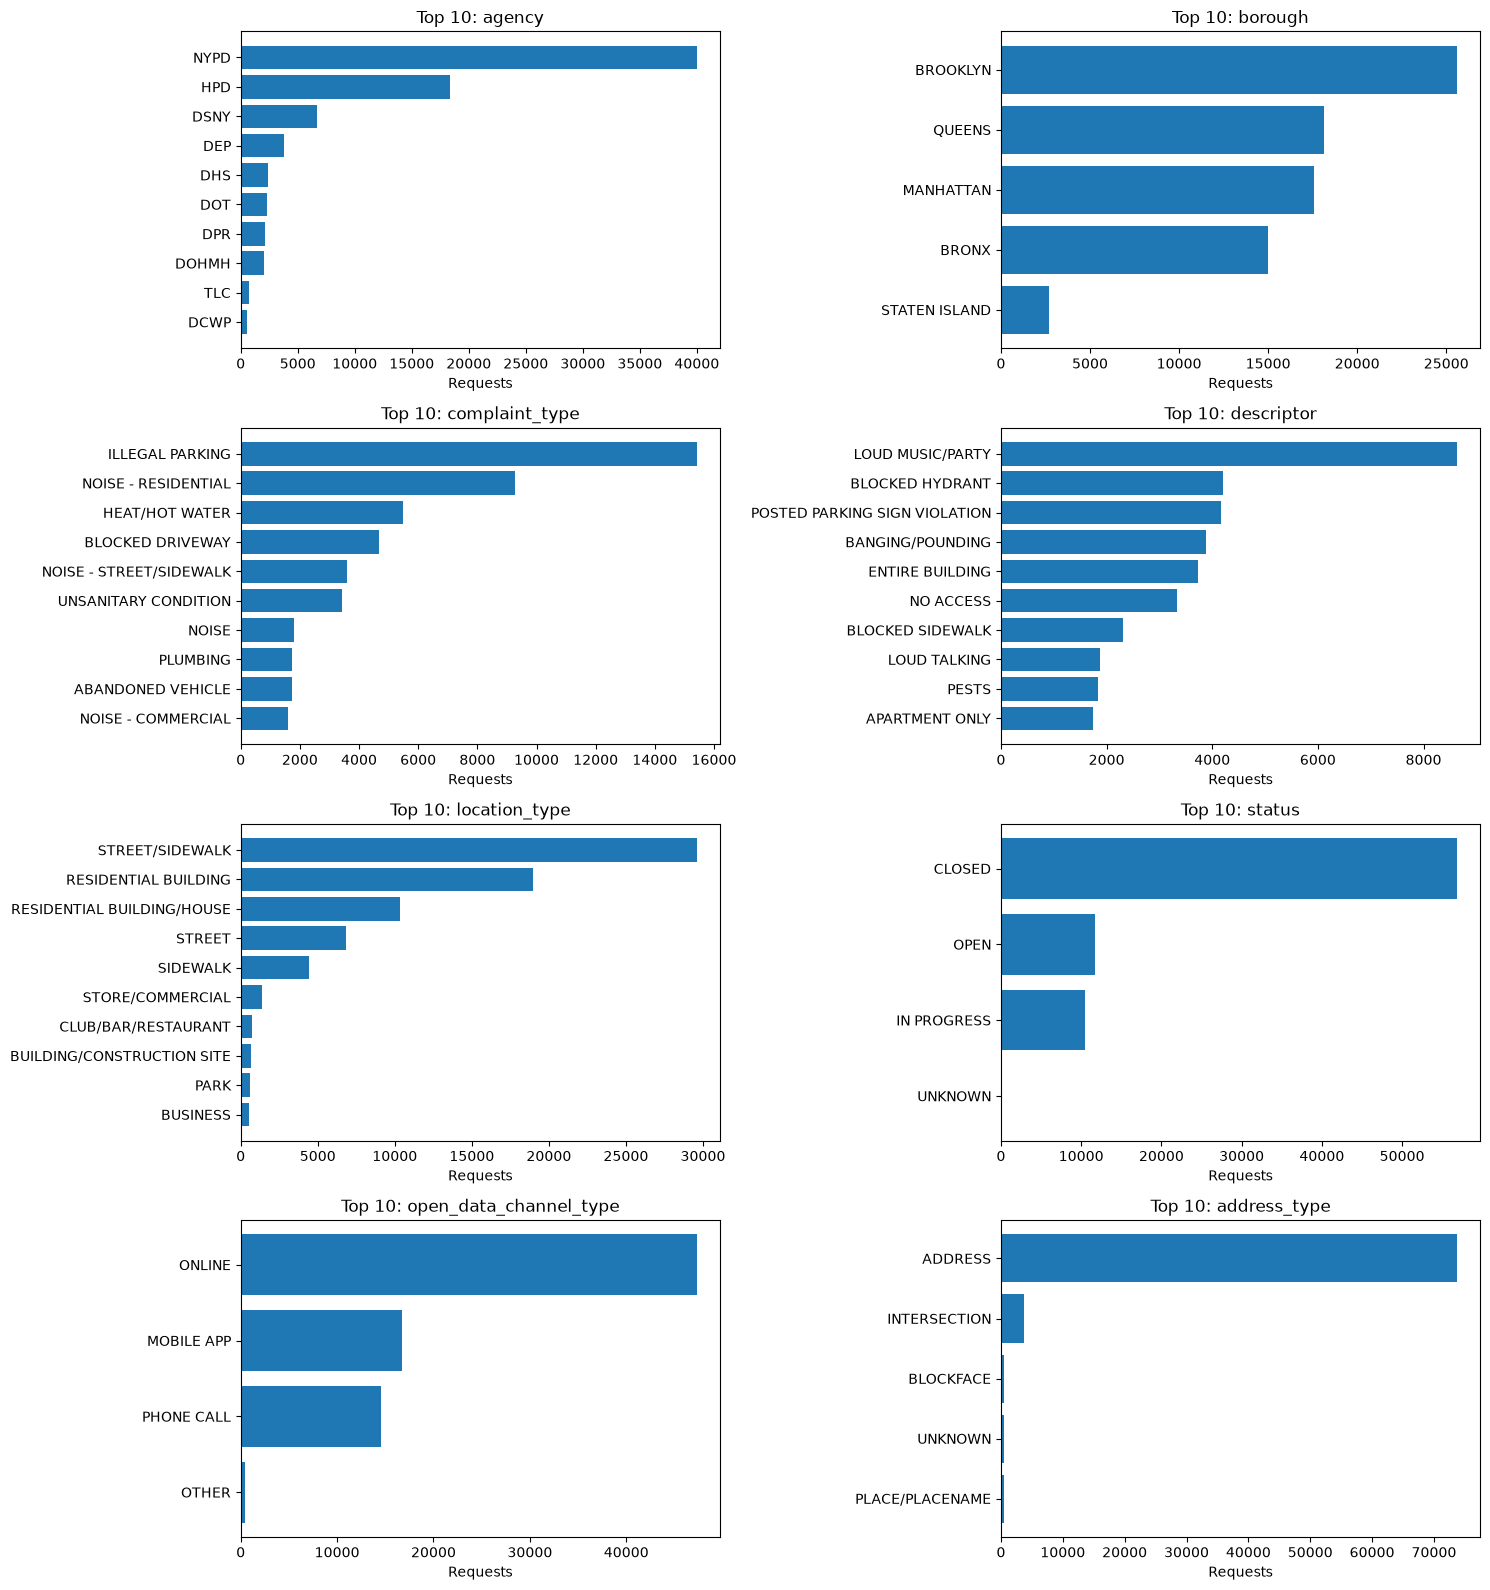

In [26]:
n_cols = 2
n_rows = (len(cat_cols) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    top = df[col].value_counts().head(10).sort_values()
    axes[i].barh(top.index.astype(str), top.values)
    axes[i].set_title(f"Top 10: {col}")
    axes[i].set_xlabel("Requests")

for j in range(len(cat_cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### When are complaints raised?

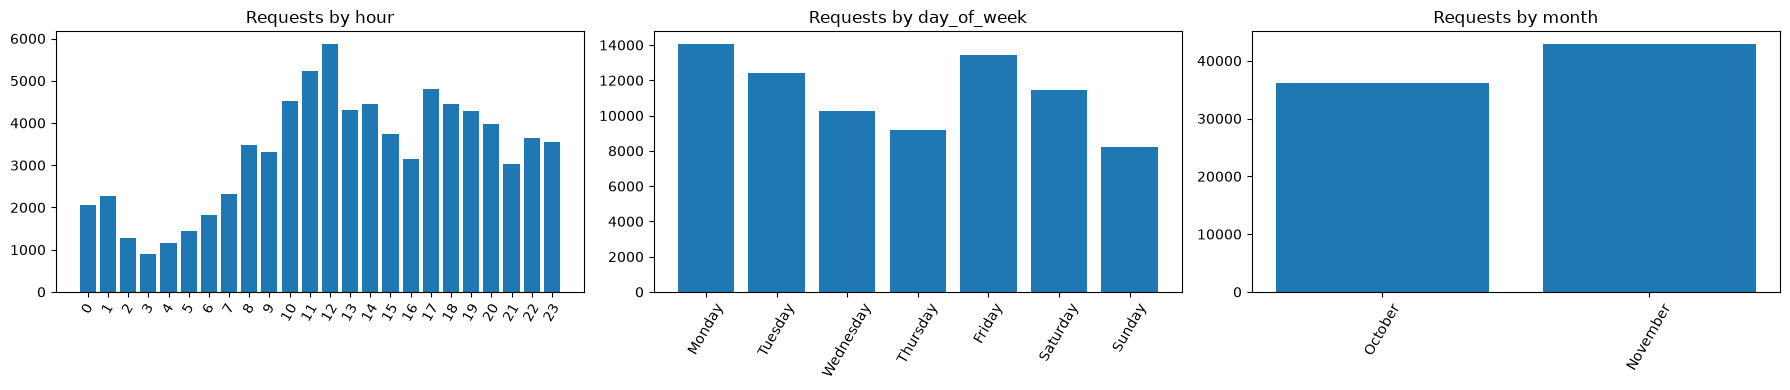

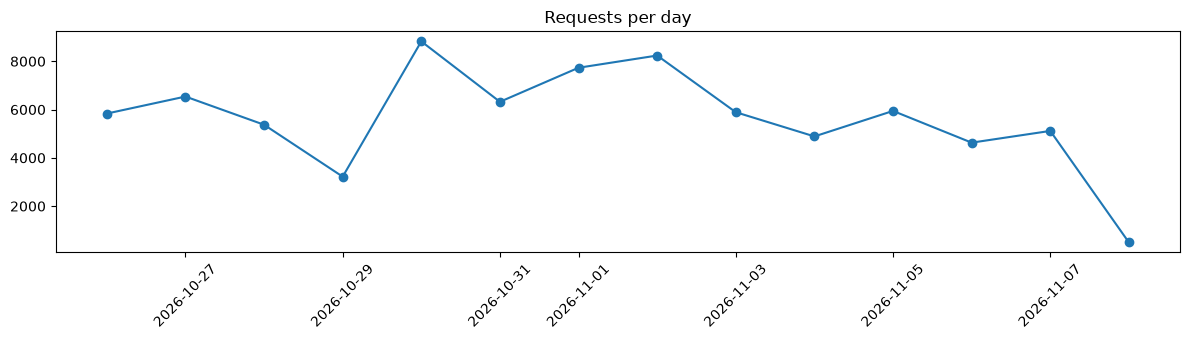

In [27]:
time_orders = {
    "hour": list(range(24)),
    "day_of_week": ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
    "month": ["January", "February", "March", "April", "May", "June", "July",
              "August", "September", "October", "November", "December"],
}

fig, axes = plt.subplots(1, len(time_orders), figsize=(18, 4))
for ax, (col, order) in zip(axes, time_orders.items()):
    counts = df[col].value_counts()
    ordered = []
    for key in order:
        if key in counts.index:
            ordered.append((key, counts[key]))
    ax.bar([str(k) for k, _ in ordered], [v for _, v in ordered])
    ax.set_title(f"Requests by {col}")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

daily = df["created_day"].value_counts().sort_index()
plt.figure(figsize=(12, 3.5))
plt.plot(daily.index, daily.values, marker="o")
plt.title("Requests per day")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Borough view: top complaint types and map-style scatter


BRONX: 15018 requests
   ILLEGAL PARKING                           2270   15.1%
   NOISE - RESIDENTIAL                       2124   14.1%
   HEAT/HOT WATER                            1712   11.4%

BROOKLYN: 25613 requests
   ILLEGAL PARKING                           6428   25.1%
   NOISE - RESIDENTIAL                       3141   12.3%
   BLOCKED DRIVEWAY                          1701    6.6%

MANHATTAN: 17560 requests
   NOISE - RESIDENTIAL                       1945   11.1%
   ILLEGAL PARKING                           1776   10.1%
   HEAT/HOT WATER                            1452    8.3%

QUEENS: 18161 requests
   ILLEGAL PARKING                           4538   25.0%
   BLOCKED DRIVEWAY                          1963   10.8%
   NOISE - RESIDENTIAL                       1708    9.4%

STATEN ISLAND: 2701 requests
   ILLEGAL PARKING                            412   15.3%
   NOISE - RESIDENTIAL                        349   12.9%
   ABANDONED VEHICLE                          160    5.9%


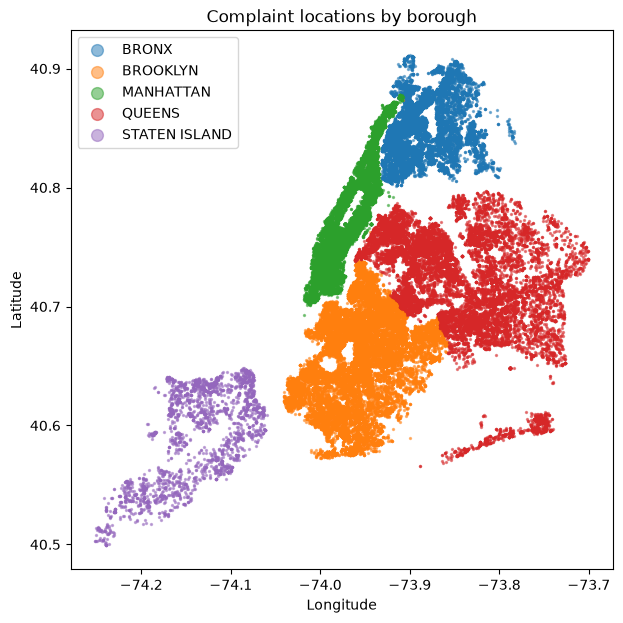

In [28]:
for b in sorted(df["borough"].unique()):
    sub = df[df["borough"] == b]
    print(f"\n{b}: {len(sub)} requests")
    for ctype, n in sub["complaint_type"].value_counts().head(3).items():
        print(f"   {ctype:40s}{n:>6d}  {n / len(sub) * 100:5.1f}%")

plt.figure(figsize=(7, 7))
for b in sorted(df["borough"].unique()):
    sub = df[df["borough"] == b]
    plt.scatter(sub["longitude"], sub["latitude"], s=2, label=b, alpha=0.5)
plt.legend(markerscale=6)
plt.title("Complaint locations by borough")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

### Agency, channel and status: share of each category per agency

In [29]:
for col in ["open_data_channel_type", "status"]:
    if col not in df.columns:
        continue
    print(f"\n=== {col} by agency (% of that agency's requests) ===")
    for agency in df["agency"].value_counts().head(6).index:
        sub = df[df["agency"] == agency]
        parts = []
        for value, n in sub[col].value_counts().items():
            parts.append(f"{value}: {n / len(sub) * 100:.0f}%")
        print(f"{agency:8s} " + " | ".join(parts))


=== open_data_channel_type by agency (% of that agency's requests) ===
NYPD     ONLINE: 57% | MOBILE APP: 33% | PHONE CALL: 10% | OTHER: 0%
HPD      ONLINE: 69% | PHONE CALL: 25% | MOBILE APP: 5%
DSNY     ONLINE: 49% | PHONE CALL: 32% | MOBILE APP: 15% | OTHER: 4%
DEP      ONLINE: 73% | PHONE CALL: 24% | MOBILE APP: 3%
DHS      ONLINE: 45% | MOBILE APP: 36% | PHONE CALL: 19%
DOT      ONLINE: 55% | PHONE CALL: 31% | MOBILE APP: 10% | OTHER: 4%

=== status by agency (% of that agency's requests) ===
NYPD     CLOSED: 98% | IN PROGRESS: 2% | UNKNOWN: 0%
HPD      OPEN: 62% | CLOSED: 38%
DSNY     CLOSED: 68% | IN PROGRESS: 28% | OPEN: 4%
DEP      IN PROGRESS: 51% | CLOSED: 49% | UNKNOWN: 0%
DHS      CLOSED: 94% | IN PROGRESS: 6%
DOT      IN PROGRESS: 65% | CLOSED: 35%


### Key findings (auto-generated)

In [30]:
for col in ["borough", "agency", "complaint_type", "location_type", "open_data_channel_type", "hour", "day_of_week"]:
    counts = df[col].value_counts()
    print(f"Most common {col}: {counts.index[0]}  ({counts.iloc[0] / len(df) * 100:.1f}% of requests)")

Most common borough: BROOKLYN  (32.4% of requests)
Most common agency: NYPD  (50.6% of requests)
Most common complaint_type: ILLEGAL PARKING  (19.5% of requests)
Most common location_type: STREET/SIDEWALK  (37.5% of requests)
Most common open_data_channel_type: ONLINE  (59.9% of requests)
Most common hour: 12  (7.4% of requests)
Most common day_of_week: Monday  (17.8% of requests)


## Save the cleaned data

In [31]:
df.to_csv("C:\\Users\\Admin\\.vscode\\AIML\\Urban Pulse Project\\nyc311_cleaned.csv", index=False)
print("Saved", df.shape)

Saved (79053, 36)


In [32]:
df.columns

Index(['unique_key', 'created_date', 'agency', 'agency_name', 'complaint_type',
       'descriptor', 'location_type', 'incident_zip', 'incident_address',
       'street_name', 'address_type', 'city', 'status', 'community_board',
       'council_district', 'police_precinct', 'borough',
       'open_data_channel_type', 'latitude', 'longitude', 'bbl',
       'resolution_description', 'resolution_action_updated_date',
       'facility_type', 'due_date', 'house_number', 'has_house_number',
       'street_type', 'resolution_category', 'has_resolution_update',
       'resolution_hours', 'hour', 'day_of_week', 'month', 'created_day',
       'is_closed'],
      dtype='str')

In [33]:
import psycopg2

# Connect to PostgreSQL
conn = psycopg2.connect(
    host="localhost",
    database="nyc_urban_pulse_db",
    user="postgres",
    password="sriO0088",
    port="5432"
)

# Create cursor
cursor = conn.cursor()

# Test connection
cursor.execute("SELECT version();")

print("PostgreSQL Connected Successfully!")
print(cursor.fetchone())



PostgreSQL Connected Successfully!
('PostgreSQL 17.11 on x86_64-windows, compiled by msvc-19.44.35228, 64-bit',)


Analyst Tasks (15 Core Investigations).


1.Total distinct request volume.

In [34]:
query = """
SELECT *
FROM service_request
LIMIT 10;
"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('71039027', datetime.datetime(2026, 11, 8, 2, 6, 22), 'NYPD', 'NEW YORK CITY POLICE DEPARTMENT', 'NOISE - RESIDENTIAL', 'LOUD TALKING', 'RESIDENTIAL BUILDING/HOUSE', 11356, '14-16 116 STREET', '116 STREET', 'ADDRESS', 'COLLEGE POINT', 'IN PROGRESS', '07 QUEENS', 19, 'PRECINCT 109', 'QUEENS', 'PHONE CALL', 40.78522096659059, -73.85127809106963, 0, 'NO RESOLUTION RECORDED', datetime.datetime(2026, 11, 8, 2, 6, 22), 'SANITATION GARAGE', datetime.datetime(2026, 12, 3, 17, 13, 53), '14-16', True, 'STREET', 'NO RESOLUTION RECORDED', False, 0.0, 2, 'Sunday', 'November', datetime.date(2026, 11, 8), False)
('71036633', datetime.datetime(2026, 11, 8, 2, 5, 58), 'NYPD', 'NEW YORK CITY POLICE DEPARTMENT', 'BLOCKED DRIVEWAY', 'NO ACCESS', 'STREET/SIDEWALK', 11419, '103-38 121 STREET', '121 STREET', 'ADDRESS', 'RICHMOND HILL', 'IN PROGRESS', '10 QUEENS', 29, 'PRECINCT 106', 'QUEENS', 'PHONE CALL', 40.68789522199386, -73.82262710323552, 4095580027, 'NO RESOLUTION RECORDED', datetime.datetime(2026, 1

2.Top 10 complaint categories by count.

In [35]:
query = """
SELECT complaint_type,
       COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_total
FROM service_request
GROUP BY complaint_type
ORDER BY requests DESC
LIMIT 10;
"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('ILLEGAL PARKING', 15424, Decimal('19.51'))
('NOISE - RESIDENTIAL', 9267, Decimal('11.72'))
('HEAT/HOT WATER', 5482, Decimal('6.93'))
('BLOCKED DRIVEWAY', 4664, Decimal('5.90'))
('NOISE - STREET/SIDEWALK', 3601, Decimal('4.56'))
('UNSANITARY CONDITION', 3428, Decimal('4.34'))
('NOISE', 1801, Decimal('2.28'))
('PLUMBING', 1748, Decimal('2.21'))
('ABANDONED VEHICLE', 1743, Decimal('2.20'))
('NOISE - COMMERCIAL', 1584, Decimal('2.00'))


3.Agency workload distribution.

In [36]:
query = """
SELECT agency,
       agency_name,
       COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_total
FROM service_request
GROUP BY agency, agency_name
ORDER BY requests DESC;
"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)


('NYPD', 'NEW YORK CITY POLICE DEPARTMENT', 40010, Decimal('50.61'))
('HPD', 'DEPARTMENT OF HOUSING PRESERVATION AND DEVELOPMENT', 18376, Decimal('23.25'))
('DSNY', 'DEPARTMENT OF SANITATION', 6677, Decimal('8.45'))
('DEP', 'DEPARTMENT OF ENVIRONMENTAL PROTECTION', 3753, Decimal('4.75'))
('DHS', 'DEPARTMENT OF HOMELESS SERVICES', 2397, Decimal('3.03'))
('DOT', 'DEPARTMENT OF TRANSPORTATION', 2344, Decimal('2.97'))
('DPR', 'DEPARTMENT OF PARKS AND RECREATION', 2108, Decimal('2.67'))
('DOHMH', 'DEPARTMENT OF HEALTH AND MENTAL HYGIENE', 2018, Decimal('2.55'))
('TLC', 'TAXI AND LIMOUSINE COMMISSION', 734, Decimal('0.93'))
('DCWP', 'DEPARTMENT OF CONSUMER AND WORKER PROTECTION', 507, Decimal('0.64'))
('EDC', 'ECONOMIC DEVELOPMENT CORPORATION', 123, Decimal('0.16'))
('OTI', 'OFFICE OF TECHNOLOGY AND INNOVATION', 6, Decimal('0.01'))


4.Request volume by borough.

In [37]:
query = """
SELECT borough,
       COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_total
FROM service_request
GROUP BY borough
ORDER BY requests DESC;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('BROOKLYN', 25613, Decimal('32.40'))
('QUEENS', 18161, Decimal('22.97'))
('MANHATTAN', 17560, Decimal('22.21'))
('BRONX', 15018, Decimal('19.00'))
('STATEN ISLAND', 2701, Decimal('3.42'))


5.Monthly request trend.

In [38]:
query = """
SELECT month,
       COUNT(*) AS requests,
       MIN(created_day) AS first_day_in_data,
       MAX(created_day) AS last_day_in_data,
       COUNT(DISTINCT created_day) AS days_covered,
       ROUND(1.0 * COUNT(*) / COUNT(DISTINCT created_day), 0) AS avg_requests_per_day
FROM service_request
GROUP BY month
ORDER BY MIN(created_day);

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('October', 36115, datetime.date(2026, 10, 26), datetime.date(2026, 10, 31), 6, Decimal('6019'))
('November', 42938, datetime.date(2026, 11, 1), datetime.date(2026, 11, 8), 8, Decimal('5367'))


6a. Demand by weekday

In [39]:
query = """
SELECT day_of_week,
       COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_total
FROM service_request
GROUP BY day_of_week
ORDER BY CASE day_of_week
           WHEN 'Monday' THEN 1 WHEN 'Tuesday' THEN 2 WHEN 'Wednesday' THEN 3
           WHEN 'Thursday' THEN 4 WHEN 'Friday' THEN 5 WHEN 'Saturday' THEN 6
           WHEN 'Sunday' THEN 7 END;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('Monday', 14074, Decimal('17.80'))
('Tuesday', 12431, Decimal('15.72'))
('Wednesday', 10260, Decimal('12.98'))
('Thursday', 9165, Decimal('11.59'))
('Friday', 13455, Decimal('17.02'))
('Saturday', 11438, Decimal('14.47'))
('Sunday', 8230, Decimal('10.41'))


6B.Demand by hour of day

In [40]:
query = """
SELECT hour,
       COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_total
FROM service_request
GROUP BY hour
ORDER BY hour;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

(0, 2059, Decimal('2.60'))
(1, 2262, Decimal('2.86'))
(2, 1280, Decimal('1.62'))
(3, 905, Decimal('1.14'))
(4, 1161, Decimal('1.47'))
(5, 1444, Decimal('1.83'))
(6, 1824, Decimal('2.31'))
(7, 2311, Decimal('2.92'))
(8, 3484, Decimal('4.41'))
(9, 3315, Decimal('4.19'))
(10, 4524, Decimal('5.72'))
(11, 5228, Decimal('6.61'))
(12, 5876, Decimal('7.43'))
(13, 4301, Decimal('5.44'))
(14, 4453, Decimal('5.63'))
(15, 3741, Decimal('4.73'))
(16, 3142, Decimal('3.97'))
(17, 4808, Decimal('6.08'))
(18, 4457, Decimal('5.64'))
(19, 4290, Decimal('5.43'))
(20, 3966, Decimal('5.02'))
(21, 3030, Decimal('3.83'))
(22, 3644, Decimal('4.61'))
(23, 3548, Decimal('4.49'))


6c. Weekday x hour grid (use for a heatmap)

In [41]:
query = """
SELECT day_of_week,
       hour,
       COUNT(*) AS requests
FROM service_request
GROUP BY day_of_week, hour
ORDER BY CASE day_of_week
           WHEN 'Monday' THEN 1 WHEN 'Tuesday' THEN 2 WHEN 'Wednesday' THEN 3
           WHEN 'Thursday' THEN 4 WHEN 'Friday' THEN 5 WHEN 'Saturday' THEN 6
           WHEN 'Sunday' THEN 7 END,
         hour;
"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('Monday', 0, 232)
('Monday', 1, 194)
('Monday', 2, 100)
('Monday', 3, 116)
('Monday', 4, 133)
('Monday', 5, 192)
('Monday', 6, 179)
('Monday', 7, 154)
('Monday', 8, 1157)
('Monday', 9, 1238)
('Monday', 10, 1538)
('Monday', 11, 1575)
('Monday', 12, 833)
('Monday', 13, 790)
('Monday', 14, 637)
('Monday', 15, 816)
('Monday', 16, 606)
('Monday', 17, 530)
('Monday', 18, 884)
('Monday', 19, 598)
('Monday', 20, 619)
('Monday', 21, 227)
('Monday', 22, 438)
('Monday', 23, 288)
('Tuesday', 0, 218)
('Tuesday', 1, 22)
('Tuesday', 2, 242)
('Tuesday', 3, 175)
('Tuesday', 4, 232)
('Tuesday', 5, 308)
('Tuesday', 6, 477)
('Tuesday', 7, 860)
('Tuesday', 8, 827)
('Tuesday', 9, 441)
('Tuesday', 10, 484)
('Tuesday', 11, 432)
('Tuesday', 12, 643)
('Tuesday', 13, 866)
('Tuesday', 14, 549)
('Tuesday', 15, 573)
('Tuesday', 16, 869)
('Tuesday', 17, 949)
('Tuesday', 18, 781)
('Tuesday', 19, 423)
('Tuesday', 20, 411)
('Tuesday', 21, 339)
('Tuesday', 22, 667)
('Tuesday', 23, 643)
('Wednesday', 0, 489)
('Wednesday

-- Definition of a "valid resolution duration":
--   * the request is closed (is_closed), AND
--   * resolution_action_updated_date is not earlier than created_date.
-- The resolution_hours column in the table is NOT used, because the cleaning step set negative
-- gaps to 0 and filled missing update dates with created_date. Durations are recomputed here.

In [42]:

query = """
CREATE OR REPLACE VIEW valid_resolutions AS
SELECT unique_key, agency, agency_name, complaint_type, borough,
  created_date, resolution_action_updated_date,
  EXTRACT(EPOCH FROM (resolution_action_updated_date - created_date)) / 3600.0 AS res_hours
FROM service_request
WHERE is_closed
  AND resolution_action_updated_date >= created_date;
"""

cursor.execute(query)
conn.commit()
print("View valid_resolutions created successfully.")



View valid_resolutions created successfully.


-- IQR fences for the valid durations (reused by section 5)

In [43]:

query = """
CREATE OR REPLACE VIEW res_fences AS
SELECT q1, q3, q3 - q1 AS iqr,
       q1 - 1.5 * (q3 - q1) AS lower_fence,
       q3 + 1.5 * (q3 - q1) AS upper_fence
FROM (SELECT PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY res_hours) AS q1,
             PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY res_hours) AS q3
      FROM valid_resolutions) t;
"""

cursor.execute(query)
conn.commit()
print("created successfully.")

created successfully.


-- Borough median point, used to spot coordinates that were filled in during cleaning

In [44]:
query = """
CREATE OR REPLACE VIEW borough_median_point AS
SELECT borough,
       PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY latitude)  AS med_lat,
       PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY longitude) AS med_lon
FROM service_request
GROUP BY borough;

CREATE OR REPLACE VIEW usable_coordinates AS
SELECT r.*
FROM service_request r
JOIN borough_median_point m ON m.borough = r.borough
WHERE NOT (r.latitude = m.med_lat AND r.longitude = m.med_lon);
"""

cursor.execute(query)
conn.commit()
print("created successfully.")

created successfully.


7.Distribution of recorded request statuses.

In [45]:
query = """
SELECT status,
       COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_total
FROM service_request
GROUP BY status
ORDER BY requests DESC;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('CLOSED', 56866, Decimal('71.93'))
('OPEN', 11676, Decimal('14.77'))
('IN PROGRESS', 10509, Decimal('13.29'))
('UNKNOWN', 2, Decimal('0.00'))


8.Descriptive statistics for valid resolution durations.

In [46]:
query = """
SELECT COUNT(*) AS valid_closed_requests,
       ROUND(AVG(res_hours)::numeric, 2)         AS mean_h,
       ROUND(STDDEV_SAMP(res_hours)::numeric, 2) AS std_h,
       ROUND(MIN(res_hours)::numeric, 2)         AS min_h,
       ROUND((PERCENTILE_CONT(0.05) WITHIN GROUP (ORDER BY res_hours))::numeric, 2) AS p05_h,
       ROUND((PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY res_hours))::numeric, 2) AS p25_h,
       ROUND((PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY res_hours))::numeric, 2) AS median_h,
       ROUND((PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY res_hours))::numeric, 2) AS p75_h,
       ROUND((PERCENTILE_CONT(0.90) WITHIN GROUP (ORDER BY res_hours))::numeric, 2) AS p90_h,
       ROUND((PERCENTILE_CONT(0.95) WITHIN GROUP (ORDER BY res_hours))::numeric, 2) AS p95_h,
       ROUND((PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY res_hours))::numeric, 2) AS p99_h,
       ROUND(MAX(res_hours)::numeric, 2)         AS max_h
FROM valid_resolutions;
"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

(56761, Decimal('13.79'), Decimal('26.96'), Decimal('0.00'), Decimal('0.19'), Decimal('0.78'), Decimal('2.42'), Decimal('12.58'), Decimal('43.16'), Decimal('68.79'), Decimal('143.81'), Decimal('203.75'))


9.Median resolution duration by complaint category

In [47]:
query = """
SELECT complaint_type,
       COUNT(*) AS valid_closed,
       ROUND((PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY res_hours))::numeric, 2) AS median_hours
FROM valid_resolutions
GROUP BY complaint_type
HAVING COUNT(*) >= 200
ORDER BY median_hours DESC;
"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('UNSANITARY CONDITION', 573, Decimal('77.01'))
('DOOR/WINDOW', 237, Decimal('77.01'))
('WATER LEAK', 230, Decimal('72.93'))
('PAINT/PLASTER', 440, Decimal('56.00'))
('PLUMBING', 443, Decimal('54.59'))
('ELECTRIC', 222, Decimal('50.07'))
('NOISE', 798, Decimal('46.21'))
('SEWER MAINTENANCE', 255, Decimal('33.62'))
('HEAT/HOT WATER', 4299, Decimal('29.33'))
('STREET CONDITION', 405, Decimal('25.19'))
('ILLEGAL DUMPING', 609, Decimal('23.67'))
('STREET SWEEPING COMPLAINT', 228, Decimal('23.63'))
('DERELICT VEHICLES', 625, Decimal('23.62'))
('MISSED COLLECTION', 416, Decimal('21.36'))
('DIRTY CONDITION', 952, Decimal('20.62'))
('OBSTRUCTION', 307, Decimal('19.36'))
('WATER MAINTENANCE', 499, Decimal('16.02'))
('HOMELESS PERSON ASSISTANCE', 1014, Decimal('8.60'))
('ENCAMPMENT', 1245, Decimal('4.73'))
('ABANDONED VEHICLE', 1729, Decimal('2.16'))
('ANIMAL-ABUSE', 316, Decimal('1.82'))
('BLOCKED DRIVEWAY', 4592, Decimal('1.59'))
('ILLEGAL PARKING', 15213, Decimal('1.41'))
('NON-EMERGENCY POLI

10.Median resolution duration by agency.

In [48]:
query = """
SELECT agency,
       COUNT(*) AS valid_closed,
       ROUND((PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY res_hours))::numeric, 2) AS median_hours,
       ROUND((PERCENTILE_CONT(0.9) WITHIN GROUP (ORDER BY res_hours))::numeric, 2) AS p90_hours
FROM valid_resolutions
GROUP BY agency
ORDER BY median_hours DESC;
"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('DOHMH', 453, Decimal('51.22'), Decimal('109.85'))
('TLC', 73, Decimal('48.71'), Decimal('72.29'))
('DOT', 809, Decimal('38.38'), Decimal('115.72'))
('HPD', 6949, Decimal('36.94'), Decimal('104.06'))
('DEP', 1843, Decimal('35.73'), Decimal('130.69'))
('DCWP', 119, Decimal('25.02'), Decimal('89.24'))
('DSNY', 4436, Decimal('19.75'), Decimal('59.93'))
('DPR', 448, Decimal('17.57'), Decimal('79.82'))
('DHS', 2259, Decimal('5.65'), Decimal('22.35'))
('NYPD', 39372, Decimal('1.34'), Decimal('6.75'))


11.IQR-based outlier investigation.

11A.IQR outlier summary

In [49]:
query = """
SELECT ROUND(f.q1::numeric, 2)          AS q1_h,
       ROUND(f.q3::numeric, 2)          AS q3_h,
       ROUND(f.iqr::numeric, 2)         AS iqr_h,
       ROUND(f.lower_fence::numeric, 2) AS lower_fence_h,
       ROUND(f.upper_fence::numeric, 2) AS upper_fence_h,
       COUNT(*) AS valid_closed,
       COUNT(*) FILTER (WHERE v.res_hours > f.upper_fence) AS high_outliers,
       ROUND(100.0 * COUNT(*) FILTER (WHERE v.res_hours > f.upper_fence) / COUNT(*), 2) AS high_outlier_pct
FROM valid_resolutions v
CROSS JOIN res_fences f
GROUP BY f.q1, f.q3, f.iqr, f.lower_fence, f.upper_fence;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

(Decimal('0.78'), Decimal('12.58'), Decimal('11.80'), Decimal('-16.92'), Decimal('30.28'), 56761, 8154, Decimal('14.37'))


11B. Where the outliers come from: by agency

In [50]:
query = """
SELECT v.agency,
       COUNT(*) AS valid_closed,
       COUNT(*) FILTER (WHERE v.res_hours > f.upper_fence) AS outliers,
       ROUND(100.0 * COUNT(*) FILTER (WHERE v.res_hours > f.upper_fence) / COUNT(*), 1) AS outlier_pct
FROM valid_resolutions v
CROSS JOIN res_fences f
GROUP BY v.agency
ORDER BY outliers DESC;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('HPD', 6949, 4178, Decimal('60.1'))
('DSNY', 4436, 1098, Decimal('24.8'))
('DEP', 1843, 1077, Decimal('58.4'))
('NYPD', 39372, 609, Decimal('1.5'))
('DOT', 809, 429, Decimal('53.0'))
('DOHMH', 453, 374, Decimal('82.6'))
('DHS', 2259, 150, Decimal('6.6'))
('DPR', 448, 137, Decimal('30.6'))
('TLC', 73, 54, Decimal('74.0'))
('DCWP', 119, 48, Decimal('40.3'))


11C.Where the outliers come from: top 10 complaint types by outlier count

In [51]:
query = """
SELECT v.complaint_type,
       COUNT(*) AS valid_closed,
       COUNT(*) FILTER (WHERE v.res_hours > f.upper_fence) AS outliers,
       ROUND(100.0 * COUNT(*) FILTER (WHERE v.res_hours > f.upper_fence) / COUNT(*), 1) AS outlier_pct
FROM valid_resolutions v
CROSS JOIN res_fences f
GROUP BY v.complaint_type
ORDER BY outliers DESC
LIMIT 10;
"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('HEAT/HOT WATER', 4299, 2056, Decimal('47.8'))
('NOISE', 798, 487, Decimal('61.0'))
('UNSANITARY CONDITION', 573, 486, Decimal('84.8'))
('PAINT/PLASTER', 440, 361, Decimal('82.0'))
('PLUMBING', 443, 333, Decimal('75.2'))
('NOISE - RESIDENTIAL', 9056, 289, Decimal('3.2'))
('DIRTY CONDITION', 952, 242, Decimal('25.4'))
('ILLEGAL DUMPING', 609, 223, Decimal('36.6'))
('DERELICT VEHICLES', 625, 215, Decimal('34.4'))
('DOOR/WINDOW', 237, 200, Decimal('84.4'))


12.Resolution-time skewness and distribution.

12A.Skewness of resolution time (population skewness, same as scipy.stats.skew)

In [52]:
query = """
WITH s AS (
    SELECT AVG(res_hours) AS mean_h, STDDEV_POP(res_hours) AS sd_h
    FROM valid_resolutions
)
SELECT ROUND(s.mean_h::numeric, 2) AS mean_h,
       ROUND((AVG(POWER(v.res_hours - s.mean_h, 3)) / POWER(s.sd_h, 3))::numeric, 3) AS skewness
FROM valid_resolutions v
CROSS JOIN s
GROUP BY s.mean_h, s.sd_h;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

(Decimal('13.79'), Decimal('3.300'))


12B.Distribution of resolution time in buckets

In [53]:
query = """
SELECT CASE WHEN res_hours <= 1  THEN '1) up to 1 hour'
            WHEN res_hours <= 6  THEN '2) 1 to 6 hours'
            WHEN res_hours <= 24 THEN '3) 6 to 24 hours'
            WHEN res_hours <= 72 THEN '4) 1 to 3 days'
            ELSE                      '5) over 3 days' END AS duration_bucket,
       COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM valid_resolutions
GROUP BY 1
ORDER BY 1;
"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('1) up to 1 hour', 17194, Decimal('30.3'))
('2) 1 to 6 hours', 20468, Decimal('36.1'))
('3) 6 to 24 hours', 8949, Decimal('15.8'))
('4) 1 to 3 days', 7570, Decimal('13.3'))
('5) over 3 days', 2580, Decimal('4.5'))


13.Geographic complaint concentration using usable coordinates or borough summaries.

13A.Borough summary and how many rows have usable (not filled-in) coordinates

In [54]:
query = """
SELECT r.borough,
       COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_total,
       COUNT(u.unique_key) AS usable_coordinates,
       ROUND(100.0 * COUNT(u.unique_key) / COUNT(*), 1) AS usable_pct
FROM service_request r
LEFT JOIN usable_coordinates u ON u.unique_key = r.unique_key
GROUP BY r.borough
ORDER BY requests DESC;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('BROOKLYN', 25613, Decimal('32.40'), 25613, Decimal('100.0'))
('QUEENS', 18161, Decimal('22.97'), 18161, Decimal('100.0'))
('MANHATTAN', 17560, Decimal('22.21'), 17439, Decimal('99.3'))
('BRONX', 15018, Decimal('19.00'), 15018, Decimal('100.0'))
('STATEN ISLAND', 2701, Decimal('3.42'), 2701, Decimal('100.0'))


13B.Top 10 zip codes

In [55]:
query = """
SELECT incident_zip,
       MIN(borough) AS borough,
       COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_total
FROM service_request
WHERE incident_zip IS NOT NULL
GROUP BY incident_zip
ORDER BY requests DESC
LIMIT 10;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

(11226, 'BROOKLYN', 1577, Decimal('1.99'))
(10002, 'MANHATTAN', 1421, Decimal('1.80'))
(10458, 'BRONX', 1379, Decimal('1.74'))
(11385, 'QUEENS', 1209, Decimal('1.53'))
(10457, 'BRONX', 1057, Decimal('1.34'))
(10456, 'BRONX', 1056, Decimal('1.34'))
(11101, 'QUEENS', 1025, Decimal('1.30'))
(10467, 'BRONX', 1019, Decimal('1.29'))
(10468, 'BRONX', 991, Decimal('1.25'))
(11214, 'BROOKLYN', 947, Decimal('1.20'))


13C. Hotspots on a roughly 1 km grid (coordinates rounded to 2 decimals), usable coordinates only

In [56]:
query = """
SELECT ROUND(latitude::numeric, 2)  AS grid_lat,
       ROUND(longitude::numeric, 2) AS grid_lon,
       COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_usable
FROM usable_coordinates
GROUP BY 1, 2
ORDER BY requests DESC
LIMIT 10;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

(Decimal('40.72'), Decimal('-73.98'), 823, Decimal('1.04'))
(Decimal('40.85'), Decimal('-73.91'), 644, Decimal('0.82'))
(Decimal('40.82'), Decimal('-73.94'), 615, Decimal('0.78'))
(Decimal('40.65'), Decimal('-73.96'), 602, Decimal('0.76'))
(Decimal('40.86'), Decimal('-73.90'), 599, Decimal('0.76'))
(Decimal('40.72'), Decimal('-73.99'), 559, Decimal('0.71'))
(Decimal('40.73'), Decimal('-73.99'), 523, Decimal('0.66'))
(Decimal('40.87'), Decimal('-73.89'), 517, Decimal('0.65'))
(Decimal('40.76'), Decimal('-73.99'), 515, Decimal('0.65'))
(Decimal('40.66'), Decimal('-73.96'), 494, Decimal('0.63'))


14.Recorded closure-rate comparison.

14A.Recorded closure rate overall

In [57]:
query = """
SELECT COUNT(*) AS requests,
       COUNT(*) FILTER (WHERE is_closed) AS closed,
       ROUND(100.0 * COUNT(*) FILTER (WHERE is_closed) / COUNT(*), 1) AS closure_rate_pct
FROM service_request;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

(79053, 56866, Decimal('71.9'))


14B. Closure rate by borough

In [58]:
query = """
SELECT borough,
       COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) FILTER (WHERE is_closed) / COUNT(*), 1) AS closure_rate_pct
FROM service_request
GROUP BY borough
ORDER BY closure_rate_pct;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('BRONX', 15018, Decimal('67.5'))
('MANHATTAN', 17560, Decimal('70.1'))
('STATEN ISLAND', 2701, Decimal('71.5'))
('BROOKLYN', 25613, Decimal('73.1'))
('QUEENS', 18161, Decimal('75.8'))


14C.Closure rate by agency

In [59]:
query = """
SELECT agency,
       COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) FILTER (WHERE is_closed) / COUNT(*), 1) AS closure_rate_pct
FROM service_request
GROUP BY agency
ORDER BY closure_rate_pct;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('OTI', 6, Decimal('0.0'))
('EDC', 123, Decimal('0.0'))
('TLC', 734, Decimal('9.9'))
('DPR', 2108, Decimal('21.3'))
('DOHMH', 2018, Decimal('22.4'))
('DCWP', 507, Decimal('23.5'))
('DOT', 2344, Decimal('34.5'))
('HPD', 18376, Decimal('37.9'))
('DEP', 3753, Decimal('49.1'))
('DSNY', 6677, Decimal('67.8'))
('DHS', 2397, Decimal('94.2'))
('NYPD', 40010, Decimal('98.4'))


14D.Lowest closure rates by complaint type (at least 200 requests)

In [60]:
query = """
SELECT complaint_type,
       COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) FILTER (WHERE is_closed) / COUNT(*), 1) AS closure_rate_pct
FROM service_request
GROUP BY complaint_type
HAVING COUNT(*) >= 200
ORDER BY closure_rate_pct
LIMIT 10;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('ROOT/SEWER/SIDEWALK CONDITION', 224, Decimal('0.0'))
('FOR HIRE VEHICLE COMPLAINT', 419, Decimal('0.0'))
('FOOD ESTABLISHMENT', 348, Decimal('0.3'))
('OVERGROWN TREE/BRANCHES', 404, Decimal('10.6'))
('GRAFFITI', 276, Decimal('12.0'))
('GENERAL', 1199, Decimal('14.8'))
('APPLIANCE', 709, Decimal('15.0'))
('UNSANITARY CONDITION', 3428, Decimal('16.7'))
('FLOORING/STAIRS', 740, Decimal('17.6'))
('DOOR/WINDOW', 1281, Decimal('18.5'))


15.Categories with both high request volume and long median resolution duration.

In [61]:
query = """
WITH volume AS (
    SELECT complaint_type,
           COUNT(*) AS requests,
           ROUND(100.0 * COUNT(*) FILTER (WHERE is_closed) / COUNT(*), 1) AS closure_rate_pct
    FROM service_request
    GROUP BY complaint_type
),
duration AS (
    SELECT complaint_type,
           COUNT(*) AS valid_closed,
           PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY res_hours) AS median_hours
    FROM valid_resolutions
    GROUP BY complaint_type
    HAVING COUNT(*) >= 100
),
params AS (
    SELECT 1000 AS min_requests, 24 AS long_hours
)
SELECT v.complaint_type,
       v.requests,
       d.valid_closed,
       ROUND(d.median_hours::numeric, 1) AS median_hours,
       v.closure_rate_pct
FROM volume v
JOIN duration d USING (complaint_type)
CROSS JOIN params p
WHERE v.requests >= p.min_requests
  AND d.median_hours >= p.long_hours
ORDER BY v.requests DESC;

"""

cursor.execute(query)
rows = cursor.fetchall()

for row in rows:
    print(row)

('HEAT/HOT WATER', 5482, 4299, Decimal('29.3'), Decimal('78.4'))
('UNSANITARY CONDITION', 3428, 573, Decimal('77.0'), Decimal('16.7'))
('NOISE', 1801, 798, Decimal('46.2'), Decimal('44.3'))
('PLUMBING', 1748, 443, Decimal('54.6'), Decimal('25.3'))
('PAINT/PLASTER', 1579, 440, Decimal('56.0'), Decimal('27.9'))
('DOOR/WINDOW', 1281, 237, Decimal('77.0'), Decimal('18.5'))
('GENERAL', 1199, 167, Decimal('63.7'), Decimal('14.8'))
('WATER LEAK', 1024, 230, Decimal('72.9'), Decimal('22.6'))


In [62]:
# Close connection
cursor.close()
conn.close()